ML Workflow:
Problem Statement
Data collection

Data Engineer
Data Analyst(Data Reading)

ML Engineer --ML Application pkl

DevOps Engineer  --->Deployment

## Data Collection

In [162]:
import pandas as pd
df = pd.read_csv('House Price Prediction Dataset (1).csv')
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


In [163]:
df.shape

(2000, 10)

In [164]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


In [165]:
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


## Quality Check

In [166]:
df.isna().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

In [167]:
 df.duplicated().sum()

np.int64(0)

In [168]:
for col in df.columns:
    print(col,df[col].unique()[:10])

Id [ 1  2  3  4  5  6  7  8  9 10]
Area [1360 4272 3592  966 4926 3944 3671 3419  630 2185]
Bedrooms [5 2 4 1 3]
Bathrooms [4 2 1 3]
Floors [3 2 1]
YearBuilt [1970 1958 1938 1902 1975 1906 1948 1925 1932 2000]
Location ['Downtown' 'Suburban' 'Urban' 'Rural']
Condition ['Excellent' 'Good' 'Fair' 'Poor']
Garage ['No' 'Yes']
Price [149919 424998 266746 244020 636056  93262 448722 594893 652878 340375]


In [169]:
df['Price'].describe()

count      2000.000000
mean     537676.855000
std      276428.845719
min       50005.000000
25%      300098.000000
50%      539254.000000
75%      780086.000000
max      999656.000000
Name: Price, dtype: float64

## Remove Unwanted Columns

In [170]:
df=df.drop('Id' ,axis=1)

In [171]:
df

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3592,2,2,3,1938,Downtown,Good,No,266746
3,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...
1995,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1062,5,1,2,1903,Rural,Poor,No,476925
1998,4062,3,1,2,1936,Urban,Excellent,Yes,161119


## EDA

Area vs Price

Text(0.5, 1.0, 'Area vs House Price')

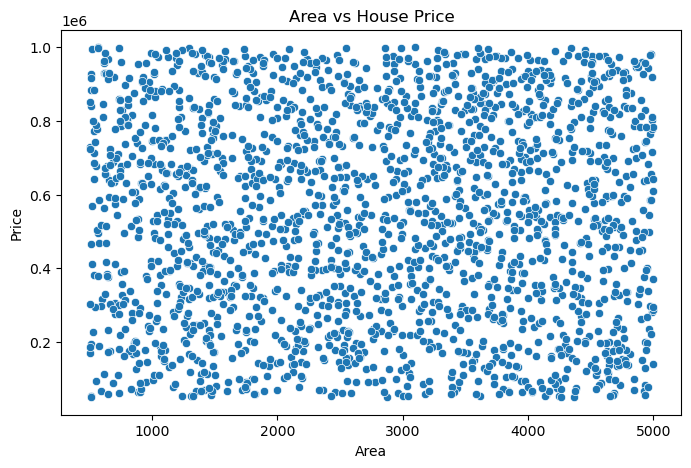

In [172]:
import seaborn as sb
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
sb.scatterplot(
    data=df,
    x='Area',
    y='Price'
)
plt.title('Area vs House Price')

## Correlation Analysis

<Axes: >

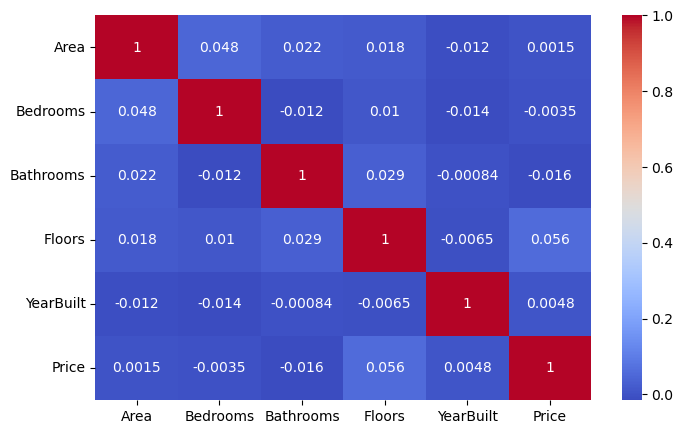

In [173]:
plt.figure(figsize=(8,5))
sb.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
    
)

## Categorical Analysis

Location Vs Price

<Axes: xlabel='Location', ylabel='Price'>

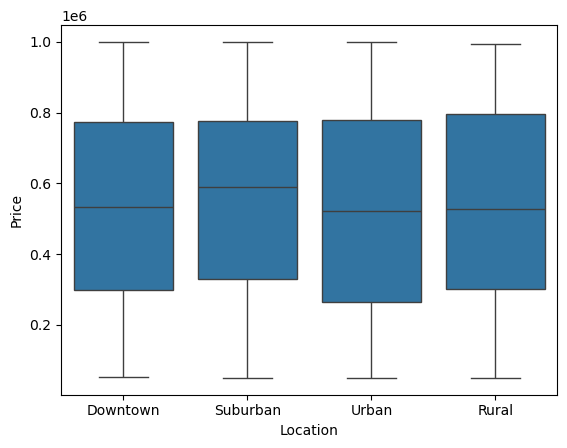

In [174]:
sb.boxplot(data=df,
          x ='Location',
          y='Price')

In [175]:
df.columns

Index(['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location',
       'Condition', 'Garage', 'Price'],
      dtype='object')

<Axes: xlabel='Condition', ylabel='Price'>

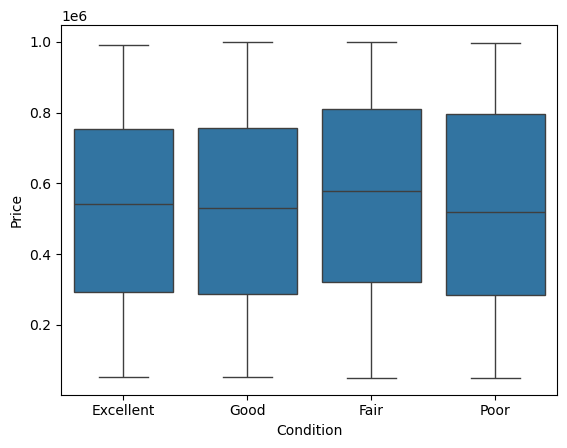

In [176]:
sb.boxplot(
    data=df,
    x='Condition',
    y='Price')

<Axes: xlabel='Garage', ylabel='Price'>

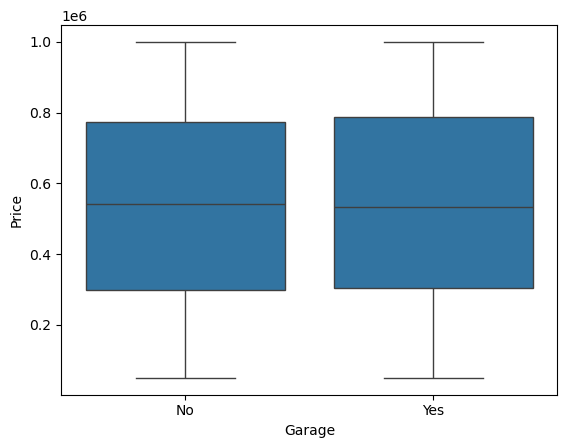

In [177]:
sb.boxplot(
    data=df,
    x='Garage',
    y='Price')

## Define Target

In [178]:
Y=df[['Price']]
X=df.drop(labels=['Price'],axis=1)

In [179]:
Y

,Price
0,149919
1,424998
2,266746
3,244020
4,636056
...,...
1995,295620
1996,580929
1997,476925
1998,161119


In [180]:
X

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage
0,1360,5,4,3,1970,Downtown,Excellent,No
1,4272,5,4,3,1958,Downtown,Excellent,No
2,3592,2,2,3,1938,Downtown,Good,No
3,966,4,2,2,1902,Suburban,Fair,Yes
4,4926,1,4,2,1975,Downtown,Fair,Yes
...,...,...,...,...,...,...,...,...
1995,4994,5,4,3,1923,Suburban,Poor,No
1996,3046,5,2,1,2019,Suburban,Poor,Yes
1997,1062,5,1,2,1903,Rural,Poor,No
1998,4062,3,1,2,1936,Urban,Excellent,Yes


## Train test split

In [181]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(X,Y,test_size=0.2,random_state=21)

In [182]:
xtrain

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
1490,-0.694465,-1.406705,-1.400273,-1.228081,-1.460171,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
965,-0.753160,-1.406705,0.403621,1.244151,0.238155,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1216,1.376860,-0.002457,-1.400273,-1.228081,-0.374356,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
500,-0.696782,0.699667,0.403621,0.008035,1.212605,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
403,0.604554,-1.406705,-1.400273,0.008035,0.989874,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48,-1.739396,-1.406705,0.403621,0.008035,1.045557,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
772,-0.244983,1.401791,0.403621,-1.228081,-0.095942,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1848,-0.074303,-0.002457,-1.400273,-1.228081,-1.014708,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1231,1.427833,0.699667,1.305568,0.008035,-0.179466,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [183]:
xtest

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
541,0.354327,-1.406705,1.305568,1.244151,-0.068100,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1211,0.348148,1.401791,-1.400273,0.008035,0.126790,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1862,1.261014,1.401791,0.403621,0.008035,-1.181757,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1094,0.325751,1.401791,1.305568,0.008035,-1.571537,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
465,-0.574758,-1.406705,-1.400273,0.008035,0.321680,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,0.311850,-0.002457,-0.498326,1.244151,-0.318673,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
985,1.010015,-1.406705,1.305568,1.244151,1.546702,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
736,-0.884453,0.699667,-0.498326,-1.228081,-0.597087,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
21,0.355871,0.699667,0.403621,-1.228081,-0.847660,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [184]:
numeric_features=[]
categorical_feature=[]

for i in X.columns:
    if X[i].dtypes=='object':
        categorical_feature.append(i)
    else:
        numeric_features.append(i)
        

In [185]:
categorical_feature

['Location', 'Condition', 'Garage']

In [186]:
numeric_features

['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']

In [187]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [188]:
# numerical_pipeline=Pipeline([
#     ('imputer',SimpleImputer(strategy='mean')),
#     ('scaler',StandardScaler())
#      ])

# categorical_pipeline=Pipeline([
#     ('imputer',SimpleImputer(strategy='most_frequent')),
#     ('encoder',OneHotEncoder(handle_unknown='ignore'))
#      ])

## Combine

In [189]:
# from sklearn.compose import ColumnTransformer
# preprocessor=ColumnTransformer(
#     [
#         ('num',numerical_pipeline,numeric_features),
#         ('cat',categorical_pipeline,categorical_feature)
#     ]
# )


In [190]:
cat_col=df[categorical_feature]

In [191]:
cat_col

,Location,Condition,Garage
0,Downtown,Excellent,No
1,Downtown,Excellent,No
2,Downtown,Good,No
3,Suburban,Fair,Yes
4,Downtown,Fair,Yes
...,...,...,...
1995,Suburban,Poor,No
1996,Suburban,Poor,Yes
1997,Rural,Poor,No
1998,Urban,Excellent,Yes


In [192]:
con_col=df[numeric_features]

In [193]:
con_col

,Area,Bedrooms,Bathrooms,Floors,YearBuilt
0,1360,5,4,3,1970
1,4272,5,4,3,1958
2,3592,2,2,3,1938
3,966,4,2,2,1902
4,4926,1,4,2,1975
...,...,...,...,...,...
1995,4994,5,4,3,1923
1996,3046,5,2,1,2019
1997,1062,5,1,2,1903
1998,4062,3,1,2,1936


In [194]:
ohe=OneHotEncoder(sparse_output=False)
Cat_encode=ohe.fit_transform(cat_col)

In [195]:
Cat_encode

array([[1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 1., 0., ..., 1., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 1., 0.]], shape=(2000, 10))

In [196]:
encoded_column=ohe.get_feature_names_out()

In [197]:
encoded_column

array(['Location_Downtown', 'Location_Rural', 'Location_Suburban',
       'Location_Urban', 'Condition_Excellent', 'Condition_Fair',
       'Condition_Good', 'Condition_Poor', 'Garage_No', 'Garage_Yes'],
      dtype=object)

In [198]:
import pandas as pd
ohe_df=pd.DataFrame(Cat_encode,columns=encoded_column)

In [199]:
ohe_df

,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
1995,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1996,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1997,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1998,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [200]:
sc=StandardScaler()
st_col=sc.fit_transform(con_col)

In [201]:
std_colm=sc.get_feature_names_out()

In [202]:
std_df=pd.DataFrame(st_col,columns=std_colm)

In [203]:
std_df

,Area,Bedrooms,Bathrooms,Floors,YearBuilt
0,-1.101471,1.401791,1.305568,1.244151,0.238155
1,1.147485,1.401791,1.305568,1.244151,-0.095942
2,0.622317,-0.704581,-0.498326,1.244151,-0.652770
3,-1.405759,0.699667,-0.498326,0.008035,-1.655061
4,1.652574,-1.406705,1.305568,0.008035,0.377363
...,...,...,...,...,...
1995,1.705091,1.401791,1.305568,1.244151,-1.070391
1996,0.200638,1.401791,-0.498326,-1.228081,1.602385
1997,-1.331618,1.401791,-1.400273,0.008035,-1.627219
1998,0.985301,-0.002457,-1.400273,0.008035,-0.708453


In [204]:
scaled_df=pd.concat([std_df,ohe_df],axis=1)

In [205]:
scaled_df.isna().sum()

Area                   0
Bedrooms               0
Bathrooms              0
Floors                 0
YearBuilt              0
Location_Downtown      0
Location_Rural         0
Location_Suburban      0
Location_Urban         0
Condition_Excellent    0
Condition_Fair         0
Condition_Good         0
Condition_Poor         0
Garage_No              0
Garage_Yes             0
dtype: int64

In [206]:
xtrain,xtest,ytrain,ytest=train_test_split(scaled_df,Y,test_size=0.2,random_state=21)

In [207]:
xtrain

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
1490,-0.694465,-1.406705,-1.400273,-1.228081,-1.460171,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
965,-0.753160,-1.406705,0.403621,1.244151,0.238155,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1216,1.376860,-0.002457,-1.400273,-1.228081,-0.374356,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
500,-0.696782,0.699667,0.403621,0.008035,1.212605,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
403,0.604554,-1.406705,-1.400273,0.008035,0.989874,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48,-1.739396,-1.406705,0.403621,0.008035,1.045557,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
772,-0.244983,1.401791,0.403621,-1.228081,-0.095942,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1848,-0.074303,-0.002457,-1.400273,-1.228081,-1.014708,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1231,1.427833,0.699667,1.305568,0.008035,-0.179466,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [208]:
xtest

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Downtown,Location_Rural,Location_Suburban,Location_Urban,Condition_Excellent,Condition_Fair,Condition_Good,Condition_Poor,Garage_No,Garage_Yes
541,0.354327,-1.406705,1.305568,1.244151,-0.068100,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1211,0.348148,1.401791,-1.400273,0.008035,0.126790,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1862,1.261014,1.401791,0.403621,0.008035,-1.181757,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1094,0.325751,1.401791,1.305568,0.008035,-1.571537,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
465,-0.574758,-1.406705,-1.400273,0.008035,0.321680,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,0.311850,-0.002457,-0.498326,1.244151,-0.318673,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
985,1.010015,-1.406705,1.305568,1.244151,1.546702,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
736,-0.884453,0.699667,-0.498326,-1.228081,-0.597087,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
21,0.355871,0.699667,0.403621,-1.228081,-0.847660,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [209]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model_lr = model.fit(xtrain, ytrain)

## Prediction

In [210]:
y_pred=model.predict(xtest)

In [211]:
y_pred

array([[521326.23556588],
       [527895.30180979],
       [525669.78587418],
       [567547.00342135],
       [550913.72861818],
       [542563.94616052],
       [552188.65555874],
       [524678.19649605],
       [535282.86345701],
       [558307.41327543],
       [567029.76900716],
       [554041.3185594 ],
       [554486.60739096],
       [519323.12490025],
       [516205.70188471],
       [560689.73225548],
       [562153.92795744],
       [504249.75512367],
       [569661.21490349],
       [549472.29401812],
       [525611.04502037],
       [549229.37104916],
       [582958.84542505],
       [518658.93298848],
       [586601.94968414],
       [518378.2738505 ],
       [537505.10259754],
       [506789.39253492],
       [546183.46419417],
       [551377.05905129],
       [524191.22249756],
       [519832.73769989],
       [539822.4490375 ],
       [534725.46615192],
       [531992.37280206],
       [496099.07615358],
       [527702.23290906],
       [577593.7718514 ],
       [5087

## Model Evalution

In [212]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
mean_absolute_error(ytest,y_pred)

230470.76447920754

In [213]:
def evalute_model(model,xtrain,xtest,ytrain,ytest):
    model.fit(xtrain,ytrain)
    predictions=model.predict(xtest)

    mae=mean_absolute_error(ytest,predictions)
    mse=mean_squared_error(ytest,predictions)

    return mae,mse

In [214]:
evalute_model(model,xtrain,xtest,ytrain,ytest)

(230470.76447920754, 72192727314.26978)

## Pick Best Model:

In [215]:
best_model = model_lr

In [216]:
lr = LinearRegression()
best_model = lr

In [217]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(xtrain, ytrain)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [218]:
import joblib

joblib.dump(
    best_model,
    'house_price_model.pkl'
)

['house_price_model.pkl']